In [81]:
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [82]:
def get_data(x):
    try: 
        return pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}_time.csv')
    except FileNotFoundError:
        return pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}.csv')

candidates = [1314, 1533, 1569, 1814, 3164, 5216, 7791]
group_candidates = [196, 1686, 4619, 5407, 5839, 7433, 2243, 6536]
filter_type = lambda x: ('replic' in x.lower()) or ('time-' in x.lower())
len(candidates), len(group_candidates)

In [83]:
len(candidates), len(group_candidates)

(7, 8)

In [84]:
def perc_sig_beta(row, org_pvalues):
    
    betas, pvalues = [], []

    for i in dict(row):
        if 'beta' in i: betas.append(row[i])
        if 'pvalue' in i: pvalues.append(row[i])
    
    #if x == 4619: print(org_pvalues, pvalues)
    
    betas = np.array([float(i) for i in betas])
    pvalues = np.array([float(i) for i in pvalues])
    org_pvalues = np.array([float(i) for i in org_pvalues]) 
    
    if (org_pvalues<=0.05).sum()==0: print(x, org_pvalues)   
    perc_sig = (pvalues<=0.05).mean()
    mean_abs = abs(betas).mean()
    mean_abs_sig = abs(betas[org_pvalues<=0.05]).mean()
    return perc_sig, mean_abs, mean_abs_sig

## Significant variable selected by the replication year

In [85]:
result = pd.DataFrame()
for x in candidates + group_candidates:
    
    data = get_data(x)
    temp = data[data['type'].apply(filter_type)].copy()
    
    res = []; switch = False; org_pvalues = []
    for i, row in temp.iterrows(): 
        if switch and row['type'] == 'Replication': 
            res.append((np.nan, np.nan, np.nan))
        elif row['type'] == 'Replication': 
            switch=True
            org_pvalues = [row[i] for i in dict(row) if 'pvalue' in i]
            res.append(perc_sig_beta(row, org_pvalues))
        else: 
            res.append(perc_sig_beta(row, org_pvalues))
    temp = temp[['type', 'year', 'r_sq_adj']]
    temp['paper'] = x
    
    if x in candidates: temp['forward_year'] = temp['year']-list(temp['year'])[0]
    else:
        st_year = temp['year'].apply(lambda x: int(x.split('_')[0]))
        temp['forward_year'] = st_year-list(st_year)[0]
    
    temp['perc_sig'] = [i[0] for i in res]
    temp['mean_abs'] = [i[1] for i in res]
    temp['mean_abs_sig'] = [i[2] for i in res]
    
    temp['forward_perc_sig'] = temp['perc_sig']-list(temp['perc_sig'])[0]
    temp['forward_mean_abs'] = temp['mean_abs']-list(temp['mean_abs'])[0]
    temp['forward_mean_abs_sig'] = temp['mean_abs_sig']-list(temp['mean_abs_sig'])[0]
    
    temp['forward_rsqadj'] = temp['r_sq_adj']-list(temp['r_sq_adj'])[0]
    temp['neg'] = temp['forward_mean_abs_sig'].apply(lambda x: 1 if x<0 else 0)
    
    result = result.append(temp)

result = result.reset_index(drop=True).copy()

In [87]:
set(candidates+group_candidates)-set(result[result['type']=='Replication']['paper'])

set()

### Percentage of Significant Variables (pvalue=0.001)

In [88]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_perc_sig'])
X = temp_data[['forward_year']]
y = temp_data['forward_perc_sig']
X.insert(0, 'constant', 1)
sm.OLS(y, X).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       forward_perc_sig   R-squared:                       0.094
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     17.15
Date:                Wed, 16 Mar 2022   Prob (F-statistic):           5.49e-05
Time:                        15:22:10   Log-Likelihood:                 60.744
No. Observations:                 167   AIC:                            -117.5
Df Residuals:                     165   BIC:                            -111.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
constant         0.0062      0.025      0.246      0.806      -0.044       0.056
forward_year    -0.0098      0.002     -4.142      0.000      -0.015      -0.005
==============================================================================
Omnibus:                        0.498   Durbin-Watson:                   0.445
Prob(Omnibus):                  0.780   Jarque-Bera (JB):                0.453
Skew:                          -0.126   Prob(JB):                        0.798
Kurtosis:                       2.961   Cond. No.                         20.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

array([[ 1.        , -0.30686969],
       [-0.30686969,  1.        ]])

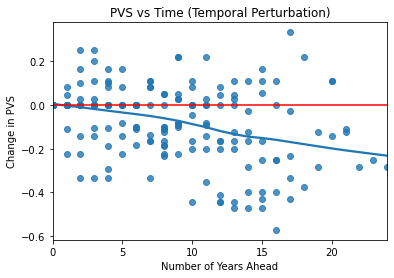

In [89]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_perc_sig'])
x = sns.regplot(x='forward_year', y='forward_perc_sig', lowess=True, data=result)
plt.xlabel('Number of Years Ahead'); 
plt.ylabel('Change in PVS')
plt.title('PVS vs Time (Temporal Perturbation)')
x.axhline(0, color='red')
np.corrcoef(temp_data['forward_year'], temp_data['forward_perc_sig'])

### Mean Absolute Value of Betas Significant in Replication (pvalue=0.026)

In [90]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_mean_abs_sig'])
X = temp_data[['forward_year']]
y = temp_data['forward_mean_abs_sig']

X.insert(0, 'constant', 1)
sm.OLS(y, X).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     forward_mean_abs_sig   R-squared:                       0.035
Model:                              OLS   Adj. R-squared:                  0.030
Method:                   Least Squares   F-statistic:                     6.061
Date:                  Wed, 16 Mar 2022   Prob (F-statistic):             0.0148
Time:                          15:23:02   Log-Likelihood:                 413.63
No. Observations:                   167   AIC:                            -823.3
Df Residuals:                       165   BIC:                            -817.0
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
constant        -0.0054      0.003     -1.780      0.077      -0.011       0.001
forward_year    -0.0007      0.000     -2.462      0.015      -0.001      -0.000
==============================================================================
Omnibus:                        8.513   Durbin-Watson:                   0.602
Prob(Omnibus):                  0.014   Jarque-Bera (JB):               15.586
Skew:                           0.143   Prob(JB):                     0.000413
Kurtosis:                       4.469   Cond. No.                         20.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

array([[ 1.        , -0.18823692],
       [-0.18823692,  1.        ]])

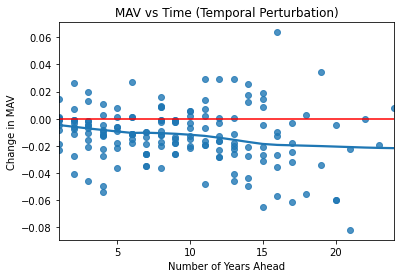

In [91]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_mean_abs_sig'])
x = sns.regplot(x='forward_year', y='forward_mean_abs_sig', lowess=True, data=temp_data)

plt.xlabel('Number of Years Ahead'); 
plt.ylabel('Change in MAV')
plt.title('MAV vs Time (Temporal Perturbation)')

x.axhline(0, color='red')
np.corrcoef(temp_data['forward_year'], temp_data['forward_mean_abs_sig'])

In [92]:
# Change in r_squared: 

array([[1.        , 0.03590212],
       [0.03590212, 1.        ]])

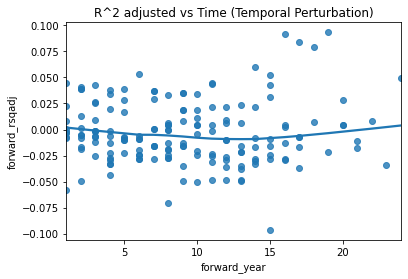

In [93]:
temp_data = result[result['type']!='Replication']
#temp_data = temp_data[temp_data['forward_year']<=5]

plt.xlabel('Number of Years Ahead'); 
plt.ylabel('Change in R^2 adjusted')
plt.title('R^2 adjusted vs Time (Temporal Perturbation)')

sns.regplot(x='forward_year', y='forward_rsqadj', lowess=True, data=temp_data)
np.corrcoef(temp_data['forward_year'], temp_data['forward_rsqadj'])

In [94]:
temp_data = temp_data[temp_data['forward_year']<=5]
X = temp_data[['forward_year']]
y = temp_data['forward_rsqadj']
X.insert(0, 'constant', 1)
sm.OLS(y, X).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         forward_rsqadj   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.017
Method:                 Least Squares   F-statistic:                    0.1272
Date:                Wed, 16 Mar 2022   Prob (F-statistic):              0.723
Time:                        15:23:17   Log-Likelihood:                 119.34
No. Observations:                  52   AIC:                            -234.7
Df Residuals:                      50   BIC:                            -230.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
constant         0.0023      0.008      0.283      0.778      -0.014       0.019
forward_year    -0.0009      0.003     -0.357      0.723      -0.006       0.004
==============================================================================
Omnibus:                        0.104   Durbin-Watson:                   0.865
Prob(Omnibus):                  0.949   Jarque-Bera (JB):                0.298
Skew:                           0.052   Prob(JB):                        0.861
Kurtosis:                       2.644   Cond. No.                         8.38
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""